# Importing libraries

In [238]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.neighbors import KNeighborsClassifier


#Loading the data

In [239]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [240]:
datapath='/content/drive/MyDrive/dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df=pd.read_csv(datapath)

#EDA

In [241]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#

In [242]:
df.shape

(7043, 21)

In [243]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [244]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [245]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [246]:
pd.set_option('display.max_columns',None)

In [247]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [248]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [249]:
df.duplicated().sum()

np.int64(0)

In [250]:
for col in df.columns:
    print(col, df[col].unique())

customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender ['Female' 'Male']
SeniorCitizen [0 1]
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (a

In [251]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")


In [252]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


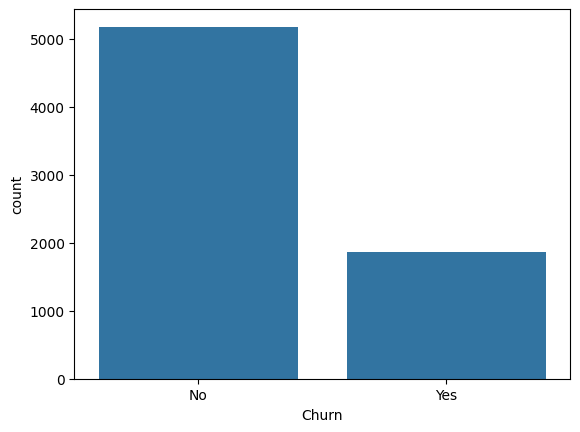

In [253]:
sns.countplot(x="Churn", data=df)
plt.show()

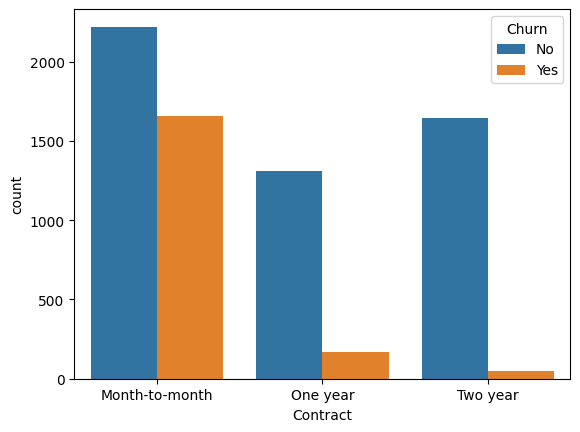

In [254]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.show()

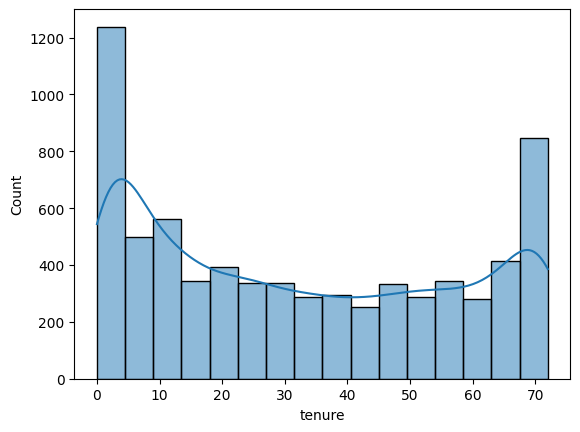

In [255]:
sns.histplot(df["tenure"], kde=True)
plt.show()

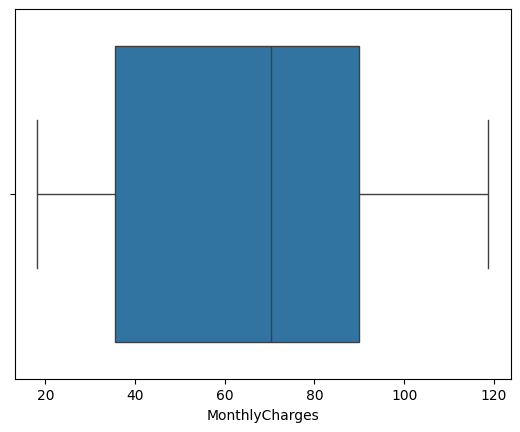

In [256]:
sns.boxplot(x=df["MonthlyCharges"])
plt.show()

In [257]:
df = df.drop_duplicates()
df = df.drop("customerID", axis=1)

In [258]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [259]:
y = y.map({"No": 0, "Yes": 1})

In [260]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y
)

In [261]:
X_train.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [262]:
X_test.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [263]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

cat_cols = X_train.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(num_cols))

print("\nCategorical Columns:")
print(list(cat_cols))

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [264]:

for col in num_cols:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())
#Median imputation was used for numerical columns because it is less affected by outliers.

In [265]:
for col in cat_cols:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])
#Mode imputation was used for categorical columns because it replaces missing values with the most frequently occurring category.

In [266]:
one_hot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore',
    drop='first'
)

X_train_encoded = one_hot_encoder.fit_transform(X_train[cat_cols])

X_test_encoded = one_hot_encoder.transform(X_test[cat_cols])

### One-Hot Encoding

One-Hot Encoding was applied to convert categorical variables into numerical format so that machine learning algorithms can process them. It creates separate binary columns for each category. The first category was dropped to avoid redundant features.

In [267]:
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=one_hot_encoder.get_feature_names_out(cat_cols),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=one_hot_encoder.get_feature_names_out(cat_cols),
    index=X_test.index
)

In [268]:
X_train_final = pd.concat(
    [X_train[num_cols], X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test[num_cols], X_test_encoded],
    axis=1
)

In [269]:
outlier_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in outlier_cols:
    Q1 = X_train_final[col].quantile(0.25)
    Q3 = X_train_final[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train_final[col] = X_train_final[col].clip(lower, upper)
    X_test_final[col] = X_test_final[col].clip(lower, upper)

In [270]:
scaler = StandardScaler()

X_train_final[num_cols] = scaler.fit_transform(
    X_train_final[num_cols]
)

X_test_final[num_cols] = scaler.transform(
    X_test_final[num_cols]
)

### Feature Scaling

StandardScaler was used to bring numerical features to a similar scale. It transforms the data to have a mean of 0 and a standard deviation of 1. Scaling is important for distance-based algorithms like KNN and helps Logistic Regression perform effectively.

In [271]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_final, y_train
)

### Handling Class Imbalance using SMOTE

The target variable contains an imbalance between customers who churn and those who do not churn. SMOTE (Synthetic Minority Over-sampling Technique) was applied to generate synthetic samples of the minority class. This helps the model learn patterns from both classes more effectively.

In [272]:
print("Training shape:", X_train_balanced.shape)
print("Testing shape:", X_test_final.shape)

print("\nClass distribution after SMOTE:")
print(y_train_balanced.value_counts())

Training shape: (8278, 30)
Testing shape: (1409, 30)

Class distribution after SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


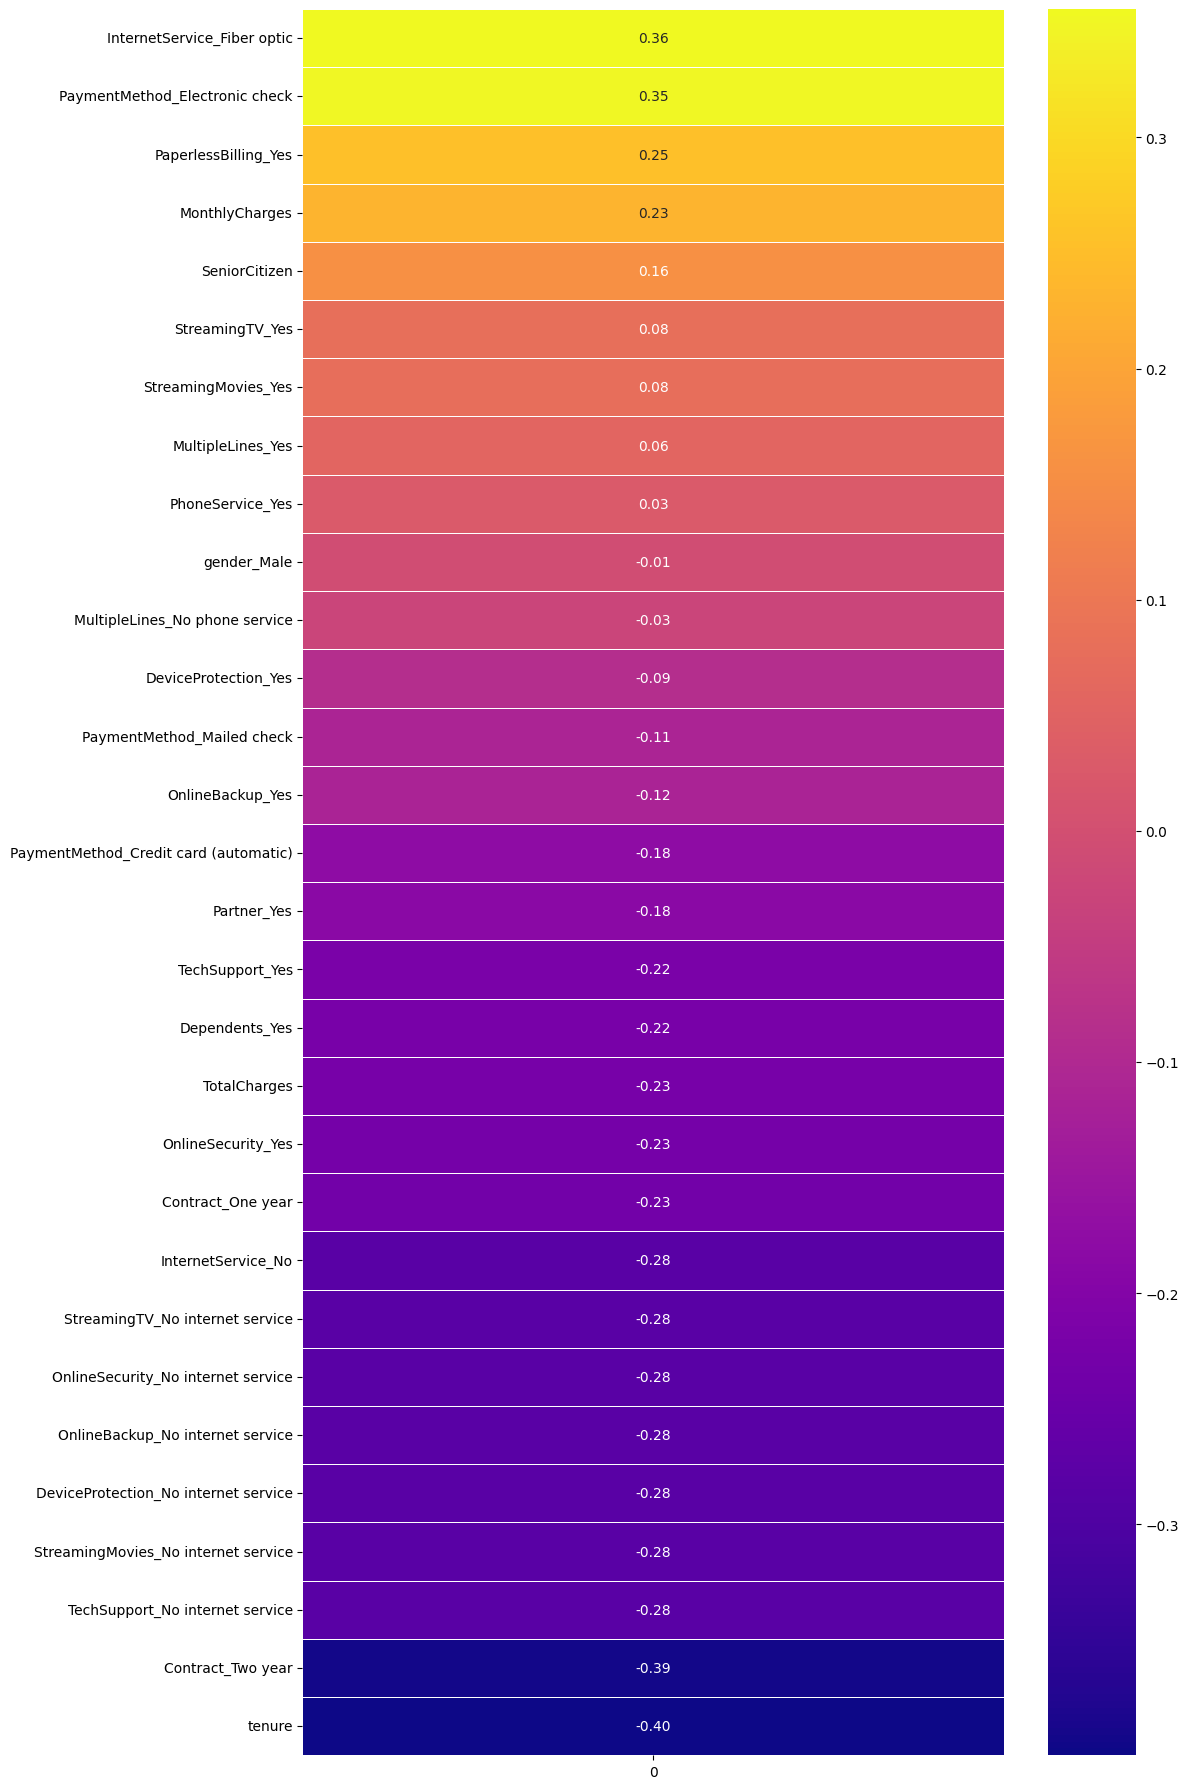

In [273]:
corr = X_train_balanced.corrwith(y_train_balanced).sort_values(ascending=False).to_frame()

plt.figure(figsize=(12,18))

sns.heatmap(
    corr,
    cmap='plasma',
    annot=True,
    linewidth=.5,
    fmt=".2f"
)

plt.tight_layout()
plt.show()

In [274]:
selected_features = ['tenure', 'Contract_Two year']

X_train_selected = X_train_balanced[selected_features]
X_test_selected = X_test_final[selected_features]

### Feature Selection

Feature selection was performed to identify the most relevant features for predicting customer churn. It helps reduce unnecessary features, simplify the model and improve model performance. The selected features were based on correlation and their relevance to the target variable.

In [275]:
log_reg=LogisticRegression()

log_reg.fit(X_train_selected,y_train_balanced)

LogisticRegression()

In [276]:
lr_prob = log_reg.predict_proba(X_test_selected)[:, 1]

In [277]:
thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    lr_threshold_pred = (lr_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, lr_threshold_pred))
    print(classification_report(y_test, lr_threshold_pred))

Threshold: 0.3
Accuracy: 0.49396735273243436
              precision    recall  f1-score   support

           0       0.97      0.32      0.48      1035
           1       0.34      0.98      0.51       374

    accuracy                           0.49      1409
   macro avg       0.66      0.65      0.49      1409
weighted avg       0.81      0.49      0.49      1409

Threshold: 0.5
Accuracy: 0.6330731014904187
              precision    recall  f1-score   support

           0       0.91      0.56      0.69      1035
           1       0.41      0.84      0.55       374

    accuracy                           0.63      1409
   macro avg       0.66      0.70      0.62      1409
weighted avg       0.77      0.63      0.65      1409

Threshold: 0.7
Accuracy: 0.765791341376863
              precision    recall  f1-score   support

           0       0.80      0.91      0.85      1035
           1       0.60      0.36      0.45       374

    accuracy                           0.77      1

### Logistic Regression

Logistic Regression was selected because customer churn is a binary classification problem with two possible outcomes: Yes or No. It uses the sigmoid function to estimate the probability of a customer leaving and classifies the result based on a decision threshold.

In [278]:
# lr_train_pred=log_reg.predict(X_train_selected)
# lr_test_pred=log_reg.predict(X_test_selected)

In [279]:
# lr_train_acc=accuracy_score(y_train_balanced,lr_train_pred)
# lr_test_acc=accuracy_score(y_test,lr_test_pred)

# print("Training Accuracy:",lr_train_acc)
# print("Testing Accuracy:",lr_test_acc)

In [280]:
cm=confusion_matrix(y_test,lr_test_pred)

print(cm)

[[577 458]
 [ 59 315]]


In [281]:
print(classification_report(y_test,lr_test_pred))

              precision    recall  f1-score   support

           0       0.91      0.56      0.69      1035
           1       0.41      0.84      0.55       374

    accuracy                           0.63      1409
   macro avg       0.66      0.70      0.62      1409
weighted avg       0.77      0.63      0.65      1409



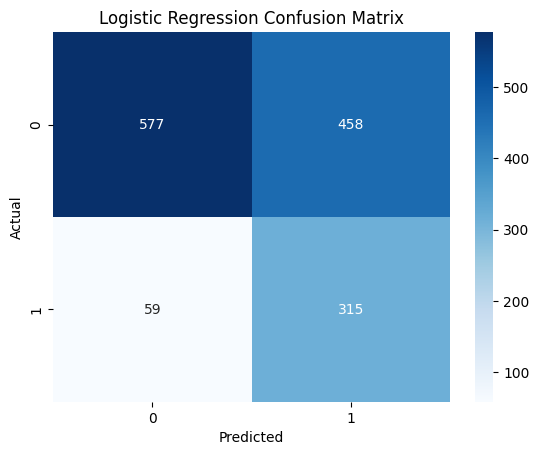

In [282]:
cm = confusion_matrix(y_test, lr_test_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [283]:
knn=KNeighborsClassifier(n_neighbors=4)

knn.fit(X_train_selected,y_train_balanced)

KNeighborsClassifier(n_neighbors=4)

### K-Nearest Neighbors (KNN)

KNN was selected as another classification algorithm to compare its performance with Logistic Regression. It classifies a customer based on the majority class among its nearest neighbors. Different K values were tested to identify the optimal value using the validation F1-score.

In [284]:
knn_train_pred=knn.predict(X_train_selected)
knn_test_pred=knn.predict(X_test_selected)

In [285]:
knn_train_acc=accuracy_score(y_train_balanced,knn_train_pred)
knn_test_acc=accuracy_score(y_test,knn_test_pred)

print("Training Accuracy:",knn_train_acc)
print("Testing Accuracy:",knn_test_acc)

Training Accuracy: 0.7350809374244986
Testing Accuracy: 0.7132718239886444


In [286]:
cm=confusion_matrix(y_test,knn_test_pred)

print(cm)

[[974  61]
 [343  31]]


In [287]:
print(classification_report(y_test,knn_test_pred))

              precision    recall  f1-score   support

           0       0.74      0.94      0.83      1035
           1       0.34      0.08      0.13       374

    accuracy                           0.71      1409
   macro avg       0.54      0.51      0.48      1409
weighted avg       0.63      0.71      0.64      1409



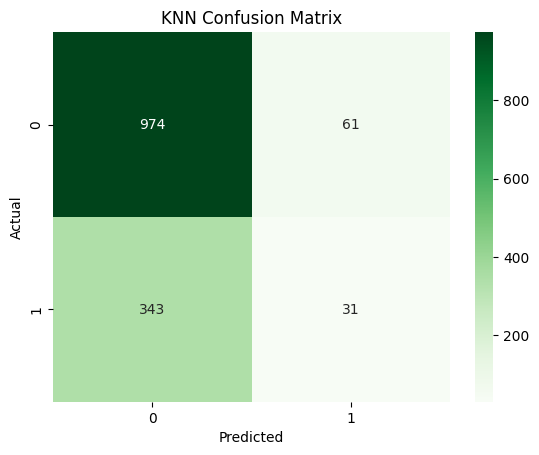

In [288]:
cm = confusion_matrix(y_test, knn_test_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### False Positive and False Negative Analysis

In customer churn prediction:

- False Positive (FP): The model predicts that a customer will churn, but the customer actually stays. This may lead to unnecessary retention offers or discounts.

- False Negative (FN): The model predicts that a customer will stay, but the customer actually churns. This may result in losing a customer without taking preventive action.

False negatives are particularly important in churn prediction because identifying customers who are likely to leave helps businesses take early retention measures.

In [289]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN'],
    'Training Accuracy': [lr_train_acc, knn_train_acc],
    'Testing Accuracy': [lr_test_acc, knn_test_acc]
})

model_comparison

,Model,Training Accuracy,Testing Accuracy
0,Logistic Regression,0.679150,0.633073
1,KNN,0.735081,0.713272


### Logistic Regression – Threshold Comparison

Logistic Regression uses predict_proba() to calculate the probability of customer churn. Different decision thresholds (0.3, 0.5 and 0.7) were tested to understand their impact on classification results.

A lower threshold predicts more customers as likely to churn, which generally increases recall.

A higher threshold predicts fewer customers as likely to churn, which generally increases precision.
